# A Case Study of Retrieving Multimedia Information

In this code example, we'll go through a step-by-step process to build a (simple) image classifier capable of identifying whether plants are healthy or not, using the Cassava dataset.

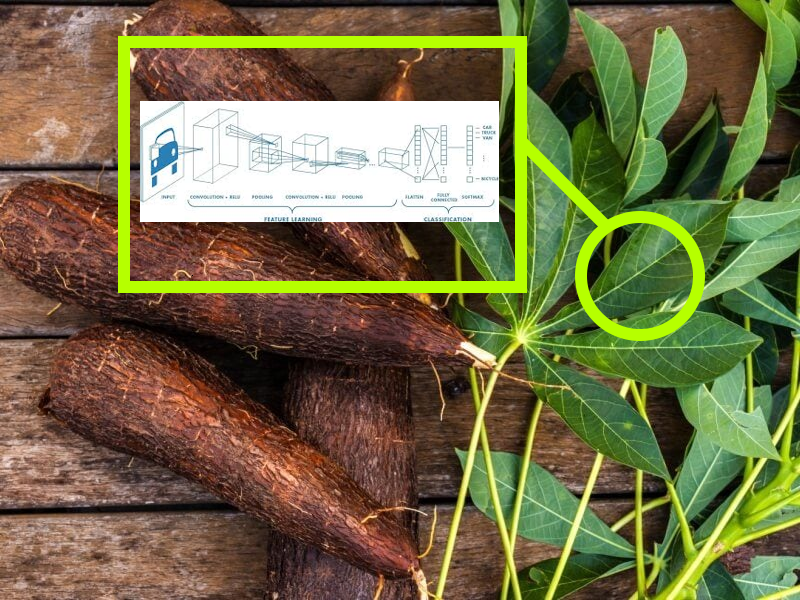

## Step 0: Libraries
We'll be using a combination of algorithmic and deep learning methods to differentiate between images. For this, we have two heavy hitters in python:
- TensorFlow (Deep Learning): One of the two most popular deep learning frameworks (the other being PyTorch). This one is built by Google's AI team. PyTorch is usually more common in research, as it exposes more of the low-level architecture, but both are very powerful.
- OpenCV: The quintessential image library for python.

> *Why use python?* Theoretically, you can use whatever you want. In practice, there are a lot of low level tasks that are required when you perform multimedia information retrieval, particularly using deep learning. Things like parallelization, device support, file handling, etc. etc. are usually too much to worry about when you already have a fairly complex task ahead of you! Python libraries let you jump right into the problem.

### A note about Google Colab
This notebook has been natively made in Google Colab (colab.research.google.com). If you run it there, you have to install nothing! You may also want to run it locally (for fun), in which case you can run it as a jupyter notebook.

In practice, Google Colab is great for prototyping. Keep in mind that you don't control how the data you put here is managed, and that you're by default using relatively slow hardware.

In [1]:
from pathlib import Path
import json
import time
import tensorflow as tf
import cv2
import numpy as np
import pandas as pd

try:
    from google.colab.patches import cv2_imshow
except ImportError:
    from IPython.display import display
    from PIL import Image

    def cv2_imshow(image):
        rgb = cv2.cvtColor(np.asarray(image, dtype=np.uint8), cv2.COLOR_BGR2RGB)
        display(Image.fromarray(rgb))

# Keep downloads, caches and trained models in the assignment's own folder.
RUN_DIR = Path.cwd() / "ass6" if (Path.cwd() / "ass6").is_dir() else Path.cwd()
DATA_DIR = RUN_DIR / ".data"
ARTIFACT_DIR = RUN_DIR / ".artifacts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
BATCH_SIZE = 32
EPOCHS = 5
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.20.0


## Step 1: Data!
What is information retrieval without information? For the purposes of this example, we'll use a publically available dataset of the ones that come bundled with Tensorflow. These are dynamically downloaded as needed.

In this case study, we're using the [cassava](https://www.kaggle.com/competitions/cassava-disease/overview) disease classification dataset. It contains images of cassava plants, which are categorized into 5 different categories:
- Diseased (with 4 different diseases)
- Healthy
For the purposes of this notebook, we're grouping all the diseased categories together.

Consider the simple scenario of having to make a code capable of detecting whether a plant is sick or not. We're effectively trying to parse information in an image, and determine if it's sufficient to assign it to our target variable.

This is called image classification, and it's one of the main tasks when it comes to image information retrieval.

> The most classic image classification task is digit classification, often using the MNIST dataset. This was one of the original success stories for the very first neural networks!

Note: If you would like, feel free to swap this dataset with any other of your choosing. You may find some inspirations in the TensorFlow datasets: https://www.tensorflow.org/datasets/catalog/overview . You may first wish to read through the entirety of the notebook.

In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load("cassava", with_info=True, data_dir=str(DATA_DIR / "cassava"))
label_eqs = {
    0: "diseased (cbb)",
    1: "diseased (cbsd)",
    2: "diseased (cgm)",
    3: "diseased (cmd)",
    4: "healthy",
}
print({split: info.splits[split].num_examples for split in ["train", "validation", "test"]})


{'train': 5656, 'validation': 1889, 'test': 1885}


In [3]:
info

tfds.core.DatasetInfo(
    name='cassava',
    full_name='cassava/0.1.0',
    description="""
    Cassava consists of leaf images for the cassava plant depicting healthy and
    four (4) disease conditions; Cassava Mosaic Disease (CMD), Cassava Bacterial
    Blight (CBB), Cassava Greem Mite (CGM) and Cassava Brown Streak Disease (CBSD).
    Dataset consists of a total of 9430 labelled images.
    The 9430 labelled images are split into a training set (5656), a test set(1885)
    and a validation set (1889). The number of images per class are unbalanced with
    the two disease classes CMD and CBSD having 72% of the images.
    """,
    homepage='https://www.kaggle.com/c/cassava-disease/overview',
    data_dir='/mnt/c/GEO/Notes/Uni/CS-homework/info retrieval/IR-Assignments/ass6/.data/cassava/cassava/0.1.0',
    file_format=tfrecord,
    download_size=1.26 GiB,
    dataset_size=1.26 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'imag

An image is just another example of data, just like words! Instead of the computer interpreting data as a character, it interprets data as a pixel brightness value. Most commonly, we use a 256 color space (0-255) divided into 3 different colors (red, green, blue). Some programs and use cases use different color spaces. Printers, for example, use CYMK (Cyan - Yellow - Magenta - Black). Another common one is HSV (Hue - Saturation - Value).

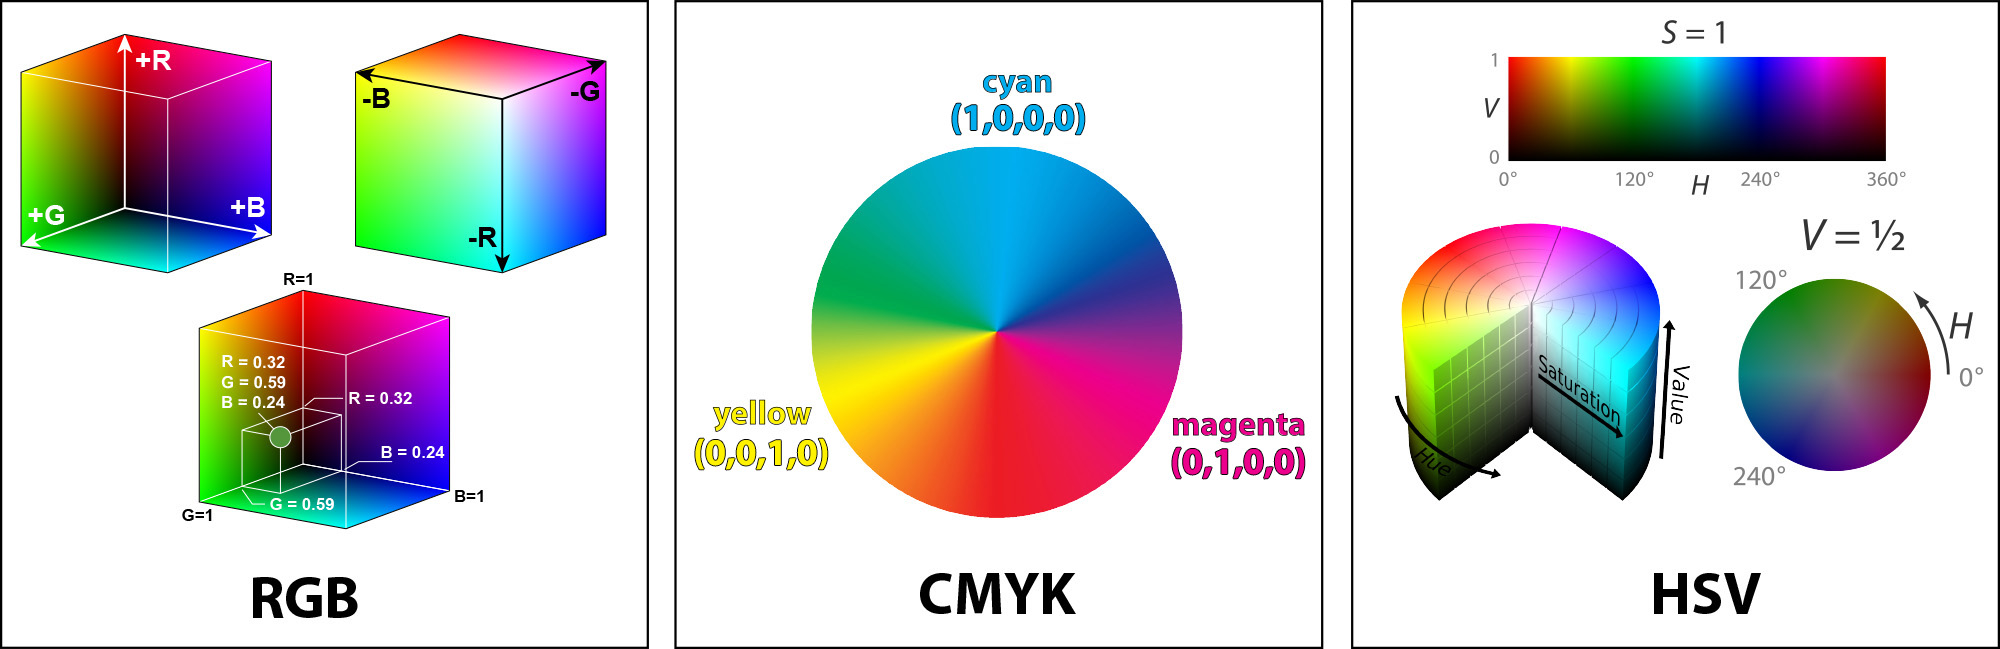

Before we talk about how to obtain relevant information from images, let's try to obtain *any* information from images by visualizing them.

In our dataset, images are contained in structures called *Tensors*. This is because these structures are very computationally efficient, but they can't be easily interpreted by OpenCV. We first convert them into a more typical way of storing images (just an array).

We also need some meaning to the image. As we discussed in class, an image is worth a thousand words: It can be describing quite a few things. Is the image an image of leaves? Of soil? Of twigs?

The target information is already stored for us, it's called a label. In this case, it's what disease the plant has.

Finally, notice we actually have multiple different splits of data: We have training data and testing data. We'll use the testing data to evaluate our solution, and the training data to design it.

> Multiple sets of data aren't necessary for creating a solution, but they are necessary to prove the solution will work. This is because it's possible for us to accidentally design a solution that works only for the data we have access to.

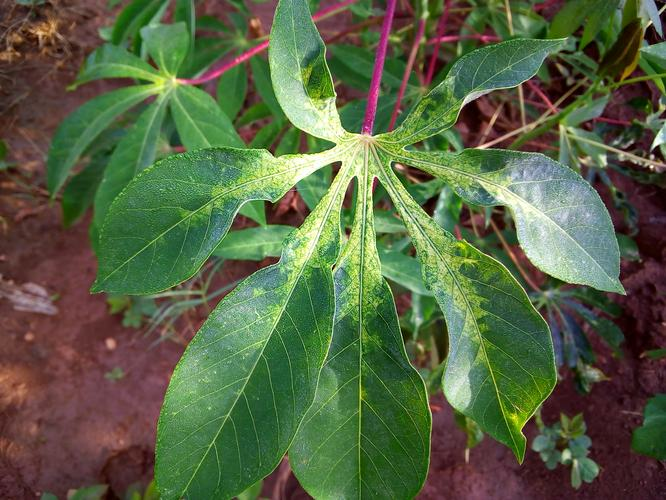

This plant is diseased (cmd)


In [4]:
def color_fix(example):
    # TFDS images are RGB; OpenCV-style display expects BGR.
    image = example["image"].numpy()
    return image[..., ::-1]

for example in dataset["train"].take(1):
    cv2_imshow(color_fix(example))
    label = int(example["label"].numpy())
    print(f"This plant is {label_eqs[label]}")


,image,image/filename,label
0,,train-cmd-2004.jpg,3 (cmd)
1,,train-cgm-762.jpg,2 (cgm)
2,,train-cmd-1726.jpg,3 (cmd)
3,,train-cmd-1556.jpg,3 (cmd)
4,,train-cmd-649.jpg,3 (cmd)
5,,train-healthy-100.jpg,4 (healthy)
6,,train-cgm-18.jpg,2 (cgm)
7,,train-cmd-2334.jpg,3 (cmd)
8,,train-cmd-380.jpg,3 (cmd)
9,,train-cbsd-174.jpg,1 (cbsd)

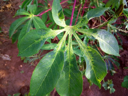
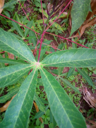
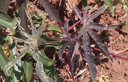
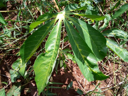
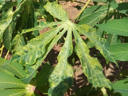
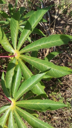
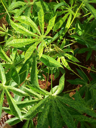
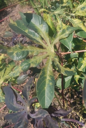
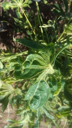
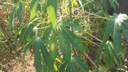

In [5]:
tfds.as_dataframe(dataset["train"].take(10), info)


## Step 2: Problem understanding
Let's dive into the problem by first trying to solve this using an algorithmic approach. Before doing anything else, I group all data with the labels I want. In this case, we don't care about what disease a plant has, we'll just try to identify whether a plant is healthy or not.



In [6]:
healthy_plants = dataset["train"].filter(lambda x: tf.equal(x["label"], 4))
healthy_examples = list(healthy_plants.take(5))

In [7]:
unhealthy_plants = dataset["train"].filter(lambda x: tf.not_equal(x["label"], 4))
unhealthy_examples = list(unhealthy_plants.take(5))

Let's look at the images, and see if we can identify anything that a _computer_ would be able to easily grab as diseased or not diseased.
- Can we do anything with color?
- Can we do anything with shapes?
- Can we do anything with brightness?

In most cases, the answer is that we need a combination of these, but for now let's not worry about trying to solve the whole problem. Let's see what the limitations of an algorithmic approach are by trying to separate a small subset of our dataset.

> You can find inspiration in image analysis techniques, such as color histograms. Statistical analysis is also a valid approach. Nowadays, machine- and deep learning are the preferred approach to image classification, though there are many benefits to knowing how to algorithmically inspect and modify images. Many recent works in deep learning (2025) ironically re-introduce these concepts explicitly to enhance results.

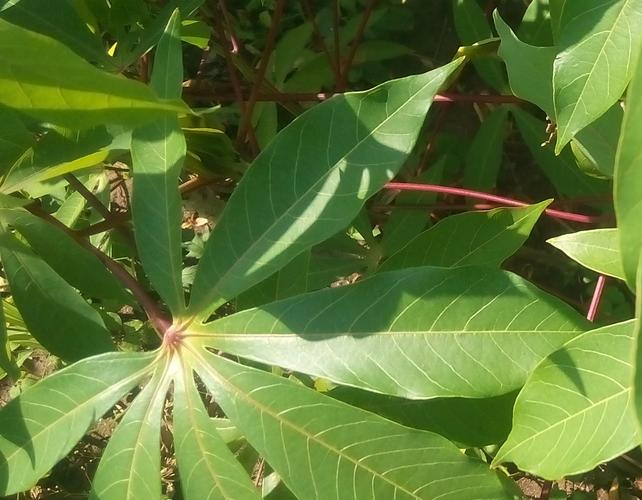

In [8]:
cv2_imshow(color_fix(healthy_examples[3]))

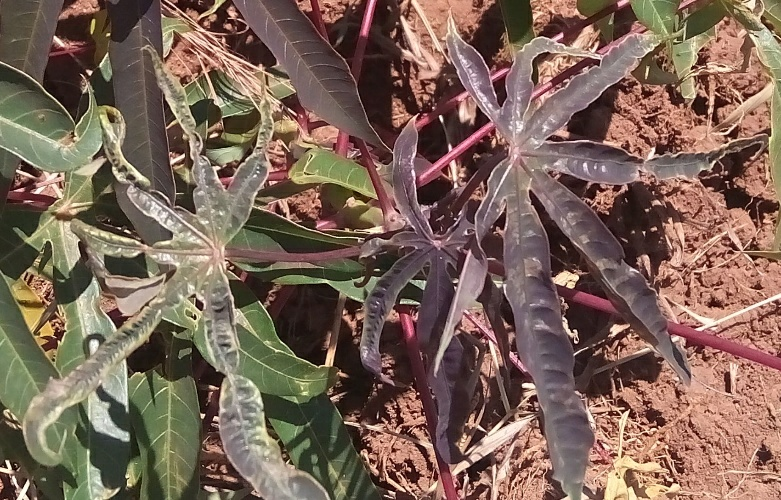

In [9]:
cv2_imshow(color_fix(unhealthy_examples[2]))

In [10]:
def scoring_function(example):
    image = color_fix(example)  # BGR order: blue=0, green=1, red=2
    green_score = np.mean(image[:, :, 1])
    red_score = np.mean(image[:, :, 2])
    healthy_score = green_score - red_score
    return 4 if healthy_score > 20 else 0

# The rule predicts healthy/unhealthy, not a particular disease subtype.
for name, example in [("Healthy example", healthy_examples[1]),
                      ("Unhealthy example", unhealthy_examples[2])]:
    prediction = "healthy" if scoring_function(example) == 4 else "unhealthy"
    print(f"{name}: predicted {prediction}")


Healthy example: predicted healthy
Unhealthy example: predicted unhealthy


## Step 3: Deep Learning solution
Deep Learning is, at its core, the application of Neural Networks to solve problems. Nowadays, we often refer to it with the catch-all of 'AI', since it has shown to be very powerful at solving many problems. While Deep Learning is *a* form of AI, there are many others.

Unfortunately for those other forms, this assignment won't explore them. Sorry!

Let's focus on building a pipeline that uses a *Convolutional Neural Network* to automatically learn what aspects of an image are relevant (features), and then leverages them to distinguish between them.

Every machine learning solution has the same steps:
- Prepare your data
- Train your model
- Evaluate your model

Each of these steps can be a whole project on their own, but for now we'll go over them very quickly.

## Prepare your data
Models require data to be presented to them in specific ways. For example, Convolutional Neural Networks expect a specific size, otherwise they run the risk of missing part of the image or of having insufficient data to work. Likewise, networks are made to create a specific output, which should be present in the data they train in (with few exceptions). In our case, our data:
- Should be resized
- Should be made into a binary label (healthy vs unhealthy).
We also generate data *batches*, which are processed at the same time to more efficiently train.

In [ ]:
def preprocess(example):
    image = tf.image.resize(example["image"], (128, 128))
    label = tf.cast(tf.equal(example["label"], 4), tf.float32)
    return image, label  # healthy=1, unhealthy=0


def prepare_split(split, training=False):
    # Map original examples directly. do not concatenate classes in blocks.
    prepared = dataset[split].map(preprocess, num_parallel_calls=2)
    cache_dir = DATA_DIR / "processed-v1"
    cache_dir.mkdir(parents=True, exist_ok=True)
    prepared = prepared.cache(str(cache_dir / split))
    if training:
        prepared = prepared.shuffle(buffer_size=512, seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return prepared.batch(BATCH_SIZE).prefetch(1).with_options(options)


binary_dataset = prepare_split("train", training=True)
binary_validation_dataset = prepare_split("validation")
print("Images: 128 x 128 x 3; binary labels: healthy=1, unhealthy=0")


Images: 128 x 128 x 3; binary labels: healthy=1, unhealthy=0


## Train your model
A model is a specific configuration of neural networks and all their associated doohickeys (**warning**: not a technical term) that function with your data. It is important to always keep in mind that all deep learning solutions are only as good as your data, so the model is not more important than preparing what goes into it.

In our case, we will use the tensorflow keras library to build our network. This is a *sequential* model, meaning that each layer takes the output of the previous one, and feeds its output to the next one -- just like making a sandwich. Some of these layers perform simple, algorithmic steps to prepare the data that go into them (doohickeys!).

The model below functions like this:
- Resize the input
- Scale the values to be between 0-1, floating.
- Convolutional Neural Network, with a filter size of 16, kernel size 3, and a rectified linear unit activation function.
- Downsample each feature map with max pooling
- Convolutional Neural Network, with a filter size of 32, kernel size 3, and a rectified linear unit activation function.
- Downsample each feature map with max pooling
- Flatten the resulting 2D array
- Neural Network with 64 neurons and a rectified linear activation function
- Neural Network with 1 neuron and a sigmoid activation function

This model is then instructed to learn using an ADAM optimizer, and with cross-entropy for its loss function.

What does this all mean?! For now, you don't have to know all of the specifics: Adjusting these values will either make the network more complex (requires more data, trains slower, but can describe more difficult features), or more simple (the opposite!). Some values are particularly appropriate for some problems, but this almost always requires adjusting the network to find them.

Feel free to modify the network below to see what happens! Some things you can try:
- Increase/decrease the number of neurons in the second to last layer.
- Change the optimizer from adam to something like rmsprop
- Add an additional Conv2D + MaxPooling2D layer before the flatten layer
- Change values! What happens if the kernel is 4 instead of 3? What happens if our filters are 64 instead of 32?




**Answers: changes to compare**

Compared with the default architecture described above, the modified model uses a first 4x4 kernel, 32/64 filters, an additional convolution/pooling pair, 128 dense neurons and RMSprop instead of Adam.

- Larger kernels examine a wider local patch but increase computation and change which spatial details are retained.
- More filters can learn more feature patterns, at additional computational cost.
- An extra convolutional layer increases capacity and can increase overfitting risk. More complexity does not guarantee better validation or test accuracy.

The experiment below trains **both** the default and modified model for five epochs on the same training split, with the same binary targets, preprocessing and random seed. It records training time, training accuracy, validation accuracy and validation loss. The test split is reserved for evaluating the modified solution afterward. Since several settings change together, this comparison measures their combined effect; it does not isolate each individual change.


In [12]:
def build_model(modified):
    tf.keras.utils.set_random_seed(SEED)
    if modified:
        layers = [
            tf.keras.layers.Conv2D(32, 4, activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Conv2D(64, 3, activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Conv2D(64, 3, activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(128, activation="relu"),
        ]
    else:
        layers = [
            tf.keras.layers.Conv2D(16, 3, activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Conv2D(32, 3, activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(64, activation="relu"),
        ]
    network = tf.keras.Sequential([
        tf.keras.Input(shape=(128, 128, 3)),
        tf.keras.layers.Rescaling(1. / 255),
        *layers,
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    network.compile(optimizer="rmsprop" if modified else "adam",
                    loss="binary_crossentropy", metrics=["accuracy"])
    return network


baseline_model = build_model(modified=False)
model = build_model(modified=True)
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 125, 125, 32)   │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,662,881 (6.34 MB)

 Trainable params: 1,662,881 (6.34 MB)

 Non-trainable params: 0 (0.00 B)

Our model right now is initiated with placeholder values that mean nothing at all. We need to fit our model to our data. This is just a single call using TensorFlow, but keep in mind a very intense mathematical process is happening just behind the courtains. It will take a little while!

By increasing the number of epochs the model trains longer. There is an optimal number here, which usually must be found. For now, use a small number.

In [13]:
training_summary = {}
histories = {}
for name, network in [("default", baseline_model), ("modified", model)]:
    tf.keras.utils.set_random_seed(SEED)
    training_input = prepare_split("train", training=True)
    print(f"\nTraining {name} model for {EPOCHS} epochs", flush=True)
    start = time.perf_counter()
    history = network.fit(training_input, validation_data=binary_validation_dataset,
                          epochs=EPOCHS, verbose=2, shuffle=False)
    histories[name] = history.history
    training_summary[name] = {
        "seconds": time.perf_counter() - start,
        "train_accuracy": float(history.history["accuracy"][-1]),
        "validation_accuracy": float(history.history["val_accuracy"][-1]),
        "validation_loss": float(history.history["val_loss"][-1]),
    }

print("\nMeasured comparison at the final epoch:")
print(pd.DataFrame(training_summary).T.to_string())
model.save(ARTIFACT_DIR / "modified.keras")
(ARTIFACT_DIR / "training_summary.json").write_text(json.dumps(training_summary, indent=2) + "\n")



Training default model for 5 epochs


Epoch 1/5


177/177 - 24s - 135ms/step - accuracy: 0.9388 - loss: 0.2187 - val_accuracy: 0.9439 - val_loss: 0.2045


Epoch 2/5


177/177 - 20s - 112ms/step - accuracy: 0.9441 - loss: 0.1981 - val_accuracy: 0.9439 - val_loss: 0.2057


...

177/177 - 46s - 263ms/step - accuracy: 0.9441 - loss: 0.2058 - val_accuracy: 0.9439 - val_loss: 0.1986


Epoch 5/5


177/177 - 46s - 259ms/step - accuracy: 0.9441 - loss: 0.1922 - val_accuracy: 0.9439 - val_loss: 0.6427



Measured comparison at the final epoch:
             seconds  train_accuracy  validation_accuracy  validation_loss
default   103.242326        0.963755             0.935416         0.227491
modified  238.551144        0.944130             0.943886         0.642748


374

## Step 4: Evaluation
Your model should achieve an accuracy of somewhere around 78% (hopefully better after you've tinkered with it), but this is only its _train_ accuracy. This is valuable as general guidance that the model is learning something, but it actually doesn't tell you if the model is capable of performing in a real-world scenario. This is because the model has already seen all the data before being asked to classify it -- in other words, it can _memorize_ this dataset!

There are also some other problems resulting from bias towards the data that you adapt the model to. To avoid falling into that trap, we make use of a dataset that is not seen during training.

> In modern workflows, we have a third split of data ('validation') which we use to adjust model parameters.

If you want to just see what your model thinks of an image instead of scoring it, you can use model.predict(array of size Xx128x128x3, where X is the batch size).

In [14]:
# Use the same label conversion and image preprocessing as training.
# This direct mapping replaces the broken label filters and preserves every test image.
binary_test_dataset = prepare_split("test")
results = model.evaluate(binary_test_dataset, return_dict=True, verbose=2)
probabilities = model.predict(binary_test_dataset, verbose=0).reshape(-1)
y_true = np.concatenate([labels.numpy() for _, labels in binary_test_dataset]).astype(int)
y_pred = (probabilities > 0.5).astype(int)
confusion = tf.math.confusion_matrix(y_true, y_pred, num_classes=2).numpy()
tn, fp, fn, tp = [int(value) for value in confusion.ravel()]
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
class_counts = np.bincount(y_true, minlength=2)
report = {
    "tensorflow_version": tf.__version__,
    "seed": SEED,
    "epochs_per_model": EPOCHS,
    "batch_size": BATCH_SIZE,
    "training_comparison": training_summary,
    "test_examples": int(len(y_true)),
    "test_class_counts_unhealthy_healthy": class_counts.tolist(),
    "test_loss": float(results["loss"]),
    "test_accuracy": float(results["accuracy"]),
    "majority_class_test_accuracy": float(class_counts.max() / len(y_true)),
    "healthy_precision": precision,
    "healthy_recall": recall,
    "healthy_f1": f1,
    "confusion_matrix_rows_actual_columns_predicted": confusion.tolist(),
}
print("\nConfusion matrix: rows actual, columns predicted; order unhealthy, healthy")
print(confusion)
print(json.dumps(report, indent=2))
(RUN_DIR / "results.json").write_text(json.dumps(report, indent=2) + "\n")


59/59 - 4s - 66ms/step - accuracy: 0.9443 - loss: 0.5143



Confusion matrix: rows actual, columns predicted; order unhealthy, healthy
[[1780    0]
 [ 105    0]]
{
  "tensorflow_version": "2.20.0",
  "seed": 42,
  "epochs_per_model": 5,
  "batch_size": 32,
  "training_comparison": {
    "default": {
      "seconds": 103.24232600200048,
      "train_accuracy": 0.9637553095817566,
      "validation_accuracy": 0.9354155659675598,
      "validation_loss": 0.22749145328998566
    },
    "modified": {
      "seconds": 238.551144380006,
      "train_accuracy": 0.9441301226615906,
      "validation_accuracy": 0.9438856244087219,
      "validation_loss": 0.642748236656189
    }
  },
  "test_examples": 1885,
  "test_class_counts_unhealthy_healthy": [
    1780,
    105
  ],
  "test_loss": 0.5143424272537231,
  "test_accuracy": 0.9442970752716064,
  "majority_class_test_accuracy": 0.9442970822281167,
  "healthy_precision": 0.0,
  "healthy_recall": 0.0,
  "healthy_f1": 0.0,
  "confusion_matrix_rows_actual_columns_predicted": [
    [
      1780,
      0
   

938

**Observed results from the completed five-epoch experiment.**

| Model | Training accuracy, final epoch | Validation accuracy | Validation loss | Observed runtime |
| --- | ---: | ---: | ---: | ---: |
| Default | 96.38% | 93.54% | 0.2275 | 103.2 s |
| Modified | 94.41% | 94.39% | 0.6427 | 238.6 s |

The modified network has slightly higher validation accuracy, but substantially worse validation loss and takes longer in this run. Its extra convolutional computation does not establish a useful improvement. These are end-to-end CPU timings including graph tracing and data pipeline work; the first model also warms the cache. Several settings changed together, so the experiment cannot isolate one setting's effect.

On **1,885 test images**, the modified model gets **94.43% accuracy**, exactly the **94.43% majority-class baseline** to rounding. The confusion matrix shows it predicts every image as unhealthy: all **105 healthy leaves are missed**. Healthy precision, recall and F1 are all zero (with zero precision used when there are no positive predictions).

Thus the classifier does not successfully distinguish healthy leaves at threshold 0.5, despite its apparently high accuracy. This directly supports our reflection about class imbalance and the need for per-class metrics. We report this failure honestly rather than treating an approximately 95% score as proof of a good classifier. A future experiment could use training-class weights or resampling and validation-based threshold selection; those are not results claimed here.

The test split was not used to fit either model. Training comparisons use validation data. The machine-readable report is saved in `ass6/results.json` when run from this repository root. A sigmoid score is not a percentage accuracy or guaranteed confidence.

## Conclusions
With this assignment, you've learned:
- How images are represented as data in computers
- The difficulty associated with categorizing the information inside images
- How to create a model that can extract relevant information from images
- How to implement a simple deep learning model

**You have one final task before leaving**! Reflect on the following questions with your partner, and write a *brief* response in your solution (add a text cell or a comment):
- We use accuracy during this case study. Is this a good metric for this problem? Why or why not? Could we use one of the metrics we've learned previously (precision, recall, etc.)?
- Are there any trade-offs of using Deep Learnings vs. an algorithmic approach?
- While it may seem crazy, ChatGPT and other similar transformer models actually use this same idea (plus or minus some doohickeys)! Do you identify any limitations in your implementations that may worry you if they were present in models being used by many people?

Below you'll find an optional part of the assignment, where you're asked to re-implement the solution but this time for 5 categories instead of 2.

Some tips:
- Temporal information is quite tricky to handle, so 'careful' if you use a dataset that requires it (by careful I mean, do not be surprised if something doesn't translate 1-to-1 -- there is no danger in loading it and seeing what happens).
- The pipeline we've used is for classification, it should work pretty much without modification for most other classification tasks.
- If your input data isn't an image, try using Dense layers instead of Conv2D layers (these are your classic Neural Networks). For your input layer, the number of neurons should be equal to the number of columns that your data type has.

**Answers**

- **Accuracy and alternatives:** Accuracy is useful but can hide class imbalance and unequal error costs. An always-majority classifier can score highly while missing the minority class. The evaluation above therefore includes a confusion matrix and healthy-class precision, recall and F1 alongside accuracy and a majority-class baseline. Here healthy is positive label 1; diseased leaves incorrectly classified as healthy are false positives for that class. Disease detection can instead be assessed with unhealthy as the positive class, stated explicitly.
- **Algorithmic rule versus deep learning:** The color rule is inexpensive, transparent and needs no fitting, but can fail when lighting, background or disease appearance changes. The CNN learns richer patterns from labeled examples, at the cost of training data and computation, and can overfit. Dataset size alone does not make an algorithmic method fail, and a neural network is not automatically reliable in real conditions. Compare on unseen data.
- **Limitations at scale:** Unrepresentative training data, overfitting and confident mistakes on unfamiliar inputs can cause systematic harm when many users depend on the result. Learned weights produce the output; hyperparameters control model design and training. A sigmoid score is not automatically calibrated confidence. This image classifier illustrates a reliability concern, but does not have the same architecture as a transformer language model.


### Optional: Modify the code to use all labels! (Instead of only diseased vs healthy, use all 5 categories)

In [15]:
# Optional multiclass extension (not implemented).
# Keep original labels 0-4, use five softmax outputs and sparse categorical cross-entropy.
